In [1]:
from functools import partial
from astropy.io import fits

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt

### FOV selection and Cartesian projection

In [14]:
flask_map = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:,1]

In [20]:
flask_map.max()

0.46320658922195435

In [2]:
example_map = hp.read_map('/data/taurus/users/WL_cosmology/data/simulations/Takahashi/realization001/weak_lensing_maps/Dirac_source_planes/allskymap_nres11r001.zs16.mag_kappa.fits')

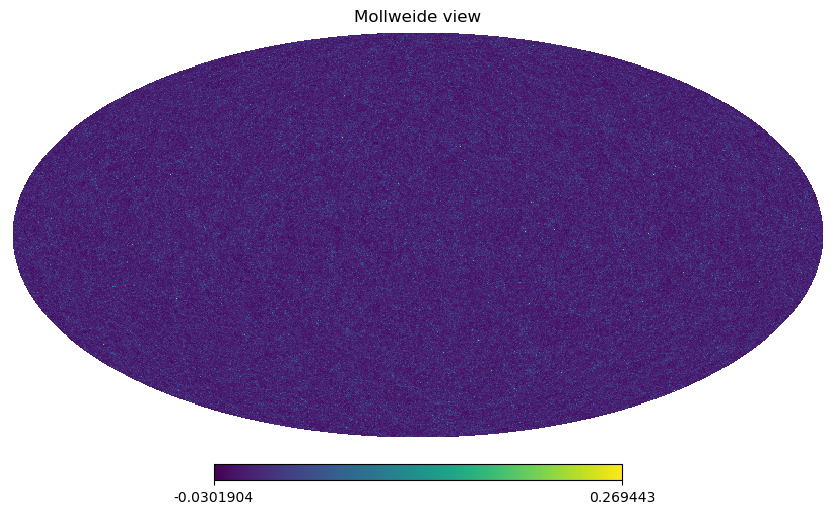

In [3]:
hp.mollview(example_map)

In [4]:
lonra = np.linspace(-180, 180, 91)
latra = np.linspace(-24, 24, 13)

In [7]:
nside = hp.get_nside(example_map)
print(nside)
print(hp.nside2resol(nside, arcmin=True))
print(hp.nside2pixarea(nside, degrees=True)*3600)

2048
1.717743205908703
2.9506417214455083


### Cartesian projection

In [21]:
n_maps = 10
n_pixels = 120
proj_array = np.zeros((n_maps*(len(lonra)-1)*(len(latra)-1), n_pixels, n_pixels))
k = 0
for m in range(n_maps):
    test_map = hp.read_map('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN/realizations_only_for_zs16/realization000%s/gaussian_allskymap_nres11r000%s.zs16.mag_kappa.fits'%(m,m))
    #test_map = hp.read_map('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_maps_takahashi_cosmo/grf_fullsky_z1z1_realization%s.fits'%(m))
    for i in range(len(lonra)-1):
        for j in range(len(latra)-1):
            # Get the cutout via a cartesian projection
            lon_view = [lonra[i], lonra[i+1]]
            lat_view = [latra[j], latra[j+1]]
            #print(lon_view)
            #print(lat_view)
            proj = hp.projector.CartesianProj(lonra=lon_view, latra=lat_view, coord=["G"], xsize=n_pixels, ysize=n_pixels)
            reproj_im = proj.projmap(test_map, vec2pix_func=partial(hp.vec2pix, nside))
            proj_array[k,:,:] = reproj_im
            k += 1

In [5]:
test_map = hp.read_map('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN/realizations_only_for_zs16/realization0000/lognormal_allskymap_nres11r0000.zs16.mag_kappa.fits')
lon_view = [0, 4]
lat_view = [24, 28]
proj = hp.projector.CartesianProj(lonra=lon_view, latra=lat_view, coord=["G"], xsize=120, ysize=120)
reproj_im_cart = proj.projmap(test_map, vec2pix_func=partial(hp.vec2pix, 2048))

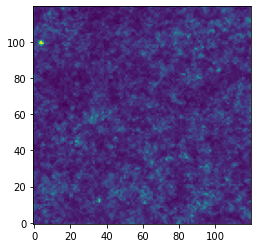

In [6]:
plt.imshow(reproj_im_cart, origin='lower', interpolation=None)

### Gnomonic projection

In [2]:
############################## fibonacci sphere ################################
# Distribute n points on a sphere with the Fibonacci algorithm, returns the    #
# positions of such points.                                                    #
# More on the algorithm at http://extremelearning.com.au                       #
#                                                                              #
# Parameters:                                                                  #
# - n (int): number of points to place on the sphere                           #
# - lonlat (bool): wheter the output has to be as longitude and latitude in    #
#                  degrees or colatitude and longitude in radians.             #
#                                                                              #
# Returns:                                                                     #
# - coords (2D array): array with shape n x 2, each row representing a point   #
################################################################################


def fibonacci_sphere(n, lonlat=True):
    goldenRatio = (1 + 5**0.5) / 2
    i = np.arange(0, n)
    phi = (2 * np.pi * i / goldenRatio) % (2 * np.pi)
    theta = np.arccos(1 - 2 * (i + 0.5) / n)
    if lonlat:
        coords = np.stack((np.degrees(phi), np.degrees(theta - np.pi / 2)), axis=-1)
    else:
        coords = np.stack((theta, phi), axis=-1)
    return coords

### Set some constants

#### Given the NSIDE of the square, this snippet checks whether the number of squares one would like to obtain from the map leads to an non-overlapping set of squares and how many squares one has to skip from the begining and end in order to achieve that

In [3]:
# Set the size of the squares in degrees
alpha = 20
# Set the resolution of the HEALPix map
NSIDE = 2048
# Set the number of squares you want to distribute on the sphere
nsquares = 60
# Set how many squares you want to skip (e.g. nskip = 1 will remove the first and the last square)
nskip = 1

 
NPIX = hp.nside2npix(NSIDE)
coords = fibonacci_sphere(nsquares, lonlat=True)
m = np.zeros(NPIX, dtype=int)
lon, lat = coords[nskip:-nskip, 0], coords[nskip:-nskip, 1]

coords_update = coords[nskip:-nskip, :]
nsquares_update = int(nsquares - 2*nskip)

# Set up number of pixels along one side of the square
n = 200
xsize=n
reso=(alpha * 60) / n


for i in range(len(lon)):
    # We get the vertices of each square (notice thet they are tilted by 45 deg)
    proj = hp.projector.GnomonicProj(rot=(lon[i], lat[i], 45), xsize=n, ysize=None, reso=reso)
    vecs = []
    for idx in [(0,0),(0,n-1),(n-1,n-1),(n-1,0)]:
        xy = proj.ij2xy(idx)
        vecs.append(proj.xy2vec(xy[0], xy[1]))
    vertices = np.array(vecs)
    # We use the vertices to get the pixel indices that are inside the square
    idx = hp.query_polygon(NSIDE, vertices, inclusive=True)
    m[idx] += 1
    

print(f'number of maps {len(lon)}')
print(f'covered area {round((len(lon)*alpha**2)/41253, 3)*100}%')
print(f'overlapping pixels: {np.sum(m==2)}')

number of maps 58
covered area 56.2%
overlapping pixels: 0


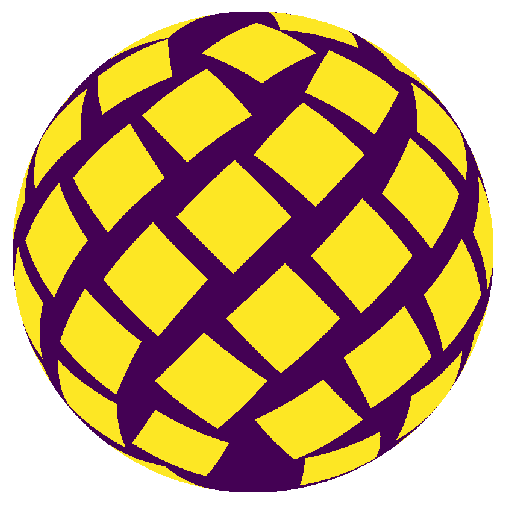

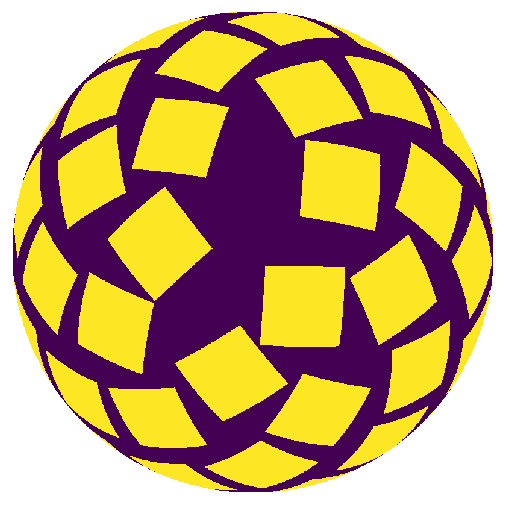

In [4]:
# View from the side
hp.orthview(m, cbar=False, half_sky = True, title = '')
#plt.savefig('fibonacci_side.pdf', dpi=400)
plt.show()
plt.close()

# view from above
hp.orthview(m, cbar=False, half_sky = True, title = '', rot=[0,-90,0])
#plt.savefig('fibonacci_top.pdf', dpi=400)
plt.show()
plt.close()

In [5]:
################################ extract region ################################
# Returns a n x n matrix containing the values of the map m inside a square    #
# patch. The square patch is centered at (lon, lat) and has a side of alpha    #
# degrees.                                                                     #
#                                                                              #
# Parameters:                                                                  #
# - m (array-like): healpix map from which extract the region                  #
# - lon (array-like or int): longitudes of the maps centers, in degrees        #
# - lat (array-like or int): latitudes of the maps centers, in degrees         #
# - phi (array-like or int): rotation angle, in degrees                        #
# - alpha (float): angular size of the maps, in degrees                        #
# - n (int): number of pixels per side of the region                           #
# - fout (str or None): path of the folder which to save the region            #
# - nest (bool): whether the angular maps are nest ordered or not              #
#                                                                              #
# Returns:                                                                     #
# - region (2D array): 2D array containing the region extracted                #
################################################################################


def extract_region(m, lon, lat, phi, alpha, n, fout=None, nest=False):
    # Compute region
    nside = hp.npix2nside(len(m))
    proj = hp.projector.GnomonicProj(
        rot=(lon, lat, phi), xsize=n, reso=(alpha * 60) / n
    )
    #region = proj.projmap(m, vec2pix_func=partial(hp.vec2pix, nside))[:][::-1]
    region = proj.projmap(m, vec2pix_func=partial(hp.vec2pix, nside))
    # Eventually save region in numpy format
    if fout:
        print(f"Saved region to {fout}")
        np.save(fout, region)
    return region

In [6]:
n_maps = 210
n_pixels = n
gnom_proj_array = np.zeros((n_maps*nsquares_update, 2, n_pixels, n_pixels))
k = 0
for m in range(n_maps):
    #test_map = hp.read_map('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN/realizations_only_for_zs16/realization00%02d/lognormal_allskymap_nres11r00%02d.zs16.mag_kappa.fits'%(m,m))
    
    test_map_bin1 = hp.read_map('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN_new_lambda_x3/realization0%03d/lognormal_allskymap_nres11r0%03d.zs10.mag_kappa.fits'%(m,m))
    test_map_bin2 = hp.read_map('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN_new_lambda_x3/realization0%03d/lognormal_allskymap_nres11r0%03d.zs16.mag_kappa.fits'%(m,m))

    #kappa_map = np.load('/data/taurus/users/dgebauer/CCNN_maps/kappa/nzmap_0%03d.npy'%(m))
    #kappa_map_bin1 = kappa_map[0]
    #kappa_map_bin2 = kappa_map[1]
    
    for i in range(coords_update.shape[0]):
        #region = extract_region(test_map, coords_update[i,0], coords_update[i,1], phi=45, alpha=4, n=n_pixels)
        #gnom_proj_array[k,:,:] = region
        
        region_bin1 = extract_region(test_map_bin1, coords_update[i,0], coords_update[i,1], phi=45, alpha=20, n=n_pixels)
        region_bin2 = extract_region(test_map_bin2, coords_update[i,0], coords_update[i,1], phi=45, alpha=20, n=n_pixels)
        gnom_proj_array[k,0,:,:] = region_bin1
        gnom_proj_array[k,1,:,:] = region_bin2

        #region_bin1 = extract_region(kappa_map_bin1, coords_update[i,0], coords_update[i,1], phi=45, alpha=20, n=n_pixels)
        #region_bin2 = extract_region(kappa_map_bin2, coords_update[i,0], coords_update[i,1], phi=45, alpha=20, n=n_pixels)
        #gnom_proj_array[k,0,:,:] = region_bin1
        #gnom_proj_array[k,1,:,:] = region_bin2
        
        k += 1

In [7]:
gnom_proj_array.shape

(12180, 2, 200, 200)

12180
(12180, 2, 200, 200)


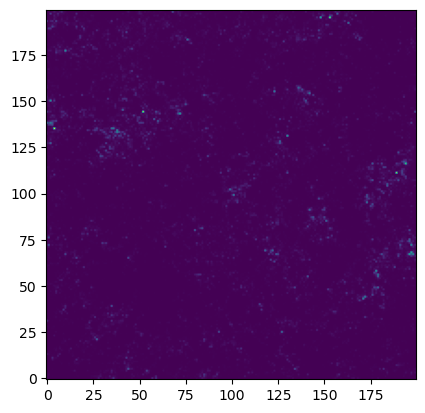

In [8]:
print(k)
print(gnom_proj_array.shape)
plt.imshow(gnom_proj_array[100,0], origin='lower', interpolation=None)

In [9]:
np.save('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_new_lambdav2_gnom_projection.npy' , gnom_proj_array)